In [4]:
import pickle
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

main_path = Path().absolute()
data_path = main_path / r"datasets"

In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

pd.set_option('display.max_columns', None)

Загрузка данных

In [5]:
with open(data_path / r"main_data.pkl", "rb") as f:
    main_data = pickle.load(f)

with open(data_path / r"coupons.pkl", "rb") as f:
    coupons = pickle.load(f)

with open(data_path / r"cards.pkl", "rb") as f:
    cards = pickle.load(f)

with open(data_path / r"favorite_dishes.pkl", "rb") as f:
    favorite_dishes = pickle.load(f)

with open(data_path / r"visits_long.pkl", "rb") as f:
    visits_long = pickle.load(f)

main_data.columns
coupons.columns
cards.columns
favorite_dishes.columns
visits_long.columns

Index(['PEOPLE_ID', 'LVL', 'mobile', 'TELEGRAM', 'last_visit',
       'first_in_periods', 'visit_cnt', 'total_paysum', 'avg_paysum',
       'avg_days_between', 'duration', 'recency', 'event'],
      dtype='object')

Index(['PEOPLE_ID', 'USED_RECENCY', 'COUPON_CNT', 'USED', 'COUPON_RECENCY'], dtype='object')

Index(['CARD_CODE', 'PEOPLE_ID'], dtype='object')

Index(['PEOPLE_ID', 'dish_group', 'favorite_dish', 'rn', 'paysum'], dtype='object')

Index(['VISIT', 'SHIFTDATE', 'BAR_NAME', 'CARD_CODE', 'VISIT_LONG'], dtype='object')

In [4]:
visits = visits_long.copy()

visits.loc[(visits['CARD_CODE'].str[0] == '8') & (visits['CARD_CODE'].str.len() == 19), "CARD_CODE"] = visits["CARD_CODE"].str[-11:]
visits.loc[(visits['CARD_CODE'].str[0] == '8') & (visits['CARD_CODE'].str.len() == 11), "CARD_CODE"] = visits["CARD_CODE"]
visits.loc[(visits['CARD_CODE'].str[0] != '8') & (~visits['CARD_CODE'].str.len().isin([11, 19])), "CARD_CODE"] = visits["CARD_CODE"].str[-8:]
visits['CARD_CODE'] = visits['CARD_CODE'].astype(pd.Int64Dtype())
visits = visits.merge(cards, on='CARD_CODE', how='inner')
visits = visits.groupby('PEOPLE_ID')['VISIT_LONG'].mean().reset_index()
# visits['PEOPLE_ID'] = visits['PEOPLE_ID']
visits

,PEOPLE_ID,VISIT_LONG
0,10000000000676,41.00
1,10000000000774,233.00
2,10000000000897,112.50
3,10000000000970,42.00
4,10000000000976,178.25
...,...,...
68552,10000002811462,274.00
68553,10000002811467,55.00
68554,10000002811468,100.00
68555,10000002811469,4.00


Обработка для товаров

In [5]:
r = {'Бар': 'Cat1', 'Кальяны': 'Cat2', 'Крейзи меню': 'Cat3'}
dish_group = favorite_dishes.groupby(['PEOPLE_ID', 'dish_group'])['paysum'].sum().reset_index()
dish_group['dish_group'] = dish_group['dish_group'].replace(r)
cat_sum = dish_group.pivot_table(index='PEOPLE_ID', columns='dish_group', values='paysum', aggfunc='sum').reset_index()[['PEOPLE_ID', 'Cat1']]
dish_group['rn'] = dish_group.groupby(['PEOPLE_ID'])['paysum'].rank(method='dense', ascending=False)
dish_group.sort_values(['PEOPLE_ID', 'rn'], inplace=True)
dish_group = dish_group.groupby('PEOPLE_ID').agg({'dish_group': lambda x: ''.join(x)}).reset_index()
dish_group['dish_group'] = dish_group['dish_group'].str.replace(' ', '')
dish_group
cat_sum

,PEOPLE_ID,dish_group
0,10000000000676,Cat3Cat1Cat2
1,10000000000774,Cat3Cat1Cat2
2,10000000000897,Cat1Cat3
3,10000000000976,Cat3Cat1Cat2
4,10000000000980,Cat3Cat1
...,...,...
45833,10000002811457,Cat1
45834,10000002811460,Cat1
45835,10000002811462,Cat3Cat1Cat2
45836,10000002811467,Cat1


dish_group,PEOPLE_ID,Cat1
0,10000000000676,11025.0
1,10000000000774,137659.0
2,10000000000897,71373.0
3,10000000000976,178945.0
4,10000000000980,1330.0
...,...,...
45833,10000002811457,3021.0
45834,10000002811460,1653.0
45835,10000002811462,26733.0
45836,10000002811467,9918.0


Обьединение данных

In [6]:
# main_data['first_visit_days'] = (main_data['last_visit'] - main_data['first_in_periods']).dt.days + main_data['recency']
# d = ['PEOPLE_ID', 'recency', 'visit_cnt', 'total_paysum', 'avg_paysum', 'avg_days_between', 'duration', 'event']
data = main_data[['PEOPLE_ID', 'LVL', 'TELEGRAM', 'total_paysum', 'visit_cnt', 'duration', 'event']]
data['TELEGRAM'] = data['TELEGRAM'].isna().astype(int)
d = ['PEOPLE_ID', 'COUPON_CNT', 'USED']
data_coupon = coupons[d]
data = data.merge(data_coupon, on=['PEOPLE_ID'], how='left')
data['COUPON_CNT'] = data['COUPON_CNT'].fillna(0)
# data['COUPON_RECENCY'] = data['COUPON_RECENCY'].fillna(180)
data['USED'] = data['USED'].fillna(0)
# data['USED_RECENCY'] = data['USED_RECENCY'].fillna(180)
data = data.merge(dish_group, on=['PEOPLE_ID'], how='left')
data['dish_group'] = data['dish_group'].fillna('unknown')
# data = data.merge(cat_sum, on='PEOPLE_ID', how='left')
# data[['Cat1', 'Cat3']] = data[['Cat1', 'Cat3']].fillna(0)
# data['Cat1'] = data['Cat1'] .fillna(0)
data = data.merge(visits, on='PEOPLE_ID', how='left')
data['VISIT_LONG'] = data['VISIT_LONG'].fillna(0)
data.drop(columns=['PEOPLE_ID'], inplace=True)

data

C:\Users\gress\AppData\Local\Temp\ipykernel_8300\1736250684.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['TELEGRAM'] = data['TELEGRAM'].isna().astype(int)


,LVL,TELEGRAM,total_paysum,visit_cnt,duration,event,COUPON_CNT,USED,dish_group,VISIT_LONG
0,L,1,4522.50,2,152.0,0.0,0.0,0.0,Cat3Cat1,12.500000
1,L,0,57640.00,3,30.0,1.0,0.0,0.0,Cat3Cat1,175.750000
2,L,1,19642.50,4,140.0,0.0,1.0,1.0,Cat3Cat1,21.800000
3,L,1,0.00,2,14.0,1.0,0.0,0.0,unknown,0.000000
4,L,0,167702.25,4,92.0,0.0,3.0,1.0,Cat1Cat3Cat2,72.000000
...,...,...,...,...,...,...,...,...,...,...
18694,XXL,1,131647.00,5,100.0,0.0,0.0,0.0,Cat3Cat1,187.600000
18695,L,0,9500.00,4,119.0,0.0,0.0,0.0,Cat1,67.500000
18696,XXL,0,192137.00,7,142.0,0.0,0.0,0.0,Cat3Cat1,33.000000
18697,L,0,1152.52,6,136.0,0.0,1.0,0.0,Cat1,1.285714


Преобработка данных

In [7]:

df = data.copy()
# df = pd.get_dummies(df, columns=['dish_group', 'LVL'], prefix=['dish_group', 'LVL'])
df = pd.get_dummies(df, columns=['dish_group', 'LVL'], prefix=['dish_group', 'LVL'], drop_first=True)
df = df.astype(float)
target_cols = ['duration', 'event']
feature_cols = [col for col in df.columns if col not in target_cols]
X_all = df[feature_cols].copy()
y_all = df[target_cols].copy()

numeric_cols = [col for col in feature_cols if 'dish_group' not in col]

bins = pd.qcut(y_all['duration'], q=10, duplicates='drop')
strata = y_all['event'].astype(int).astype(str) + "_" + bins.astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.4, random_state=42, stratify=strata
)

scaler = StandardScaler()
# X_train[numeric_cols] = X_train[numeric_cols].astype(float)
# X_test[numeric_cols] = X_test[numeric_cols].astype(float)
X_train.loc[:, numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test.loc[:, numeric_cols] = scaler.transform(X_test[numeric_cols])

Архитектура модели

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models, Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2

input_dim = X_train.shape[1]     
model = Sequential([
    Dense(128, activation="relu", input_shape=(input_dim,), kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dense(1)  
])

model.summary()
input_dim

c:\Users\gress\anaconda3\envs\tf\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,441 (52.50 KB)

 Trainable params: 13,441 (52.50 KB)

 Non-trainable params: 0 (0.00 B)

23

Функция потерь Кокса

In [9]:
def cox_ph_loss(y_true, y_pred):
    # y_true: shape (batch_size, 2) → [:, 0]=duration, [:, 1]=event
    # y_pred: shape (batch_size, 1)

    events = tf.cast(y_true[:, 1], dtype=tf.float32)
    risk = tf.squeeze(y_pred, axis=-1)

    # Сортируем по убыванию времени
    order = tf.argsort(y_true[:, 0], direction='DESCENDING')
    risk_ordered = tf.gather(risk, order)
    events_ordered = tf.gather(events, order)

    hazard_ratio = tf.exp(risk_ordered)
    log_cumsum = tf.math.log(tf.math.cumsum(hazard_ratio))
    diff = risk_ordered - log_cumsum
    loss = -tf.reduce_mean(diff * events_ordered)

    return loss


test_pred = tf.constant([[0.0], [1.0], [2.0]], dtype=tf.float32)       
test_y = tf.constant([[1, 5.0], [0, 6.0], [1, 6.0]], dtype=tf.float32)  
print("Loss на тестовом batch:", cox_ph_loss(test_y, test_pred).numpy())

Loss на тестовом batch: 3.0690677


Обучение модели

In [10]:
from sklearn.preprocessing import StandardScaler

from lifelines import KaplanMeierFitter
km = KaplanMeierFitter()

dur_tr = y_train['duration'].values
evt_tr = y_train['event'].values
cens_ind = 1 - evt_tr 

km.fit(durations=dur_tr, event_observed=cens_ind) 
G = np.clip(km.predict(dur_tr).values, 1e-3, 1.0)  
w_ipcw = 1.0 / G
w_train_ipcw = np.where(evt_tr==1, w_ipcw, 1.0).astype('float32')

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_test)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), 
              loss=cox_ph_loss)

history = model.fit(
    X_train.values, y_train.values,
    batch_size=32, 

    epochs=100,
    verbose=2,
    sample_weight=w_train_ipcw,
    validation_data=(X_val_scaled, y_test.values)
)

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 11219 total observations, 2151 right-censored observations>

Epoch 1/100
351/351 - 2s - 4ms/step - loss: 0.7716 - val_loss: 0.7296
Epoch 2/100
351/351 - 1s - 2ms/step - loss: 0.7359 - val_loss: 0.7044
Epoch 3/100
351/351 - 1s - 2ms/step - loss: 0.7108 - val_loss: 0.6856
Epoch 4/100
351/351 - 1s - 2ms/step - loss: 0.6935 - val_loss: 0.6715
Epoch 5/100
351/351 - 1s - 2ms/step - loss: 0.6811 - val_loss: 0.6577
Epoch 6/100
351/351 - 1s - 2ms/step - loss: 0.6681 - val_loss: 0.6491
Epoch 7/100
351/351 - 1s - 2ms/step - loss: 0.6577 - val_loss: 0.6396
Epoch 8/100
351/351 - 1s - 2ms/step - loss: 0.6540 - val_loss: 0.6319
Epoch 9/100
351/351 - 1s - 3ms/step - loss: 0.6467 - val_loss: 0.6253
Epoch 10/100
351/351 - 1s - 2ms/step - loss: 0.6420 - val_loss: 0.6181
Epoch 11/100
351/351 - 1s - 2ms/step - loss: 0.6350 - val_loss: 0.6126
Epoch 12/100
351/351 - 1s - 2ms/step - loss: 0.6291 - val_loss: 0.6087
Epoch 13/100
351/351 - 1s - 2ms/step - loss: 0.6257 - val_loss: 0.6034
Epoch 14/100
351/351 - 1s - 2ms/step - loss: 0.6215 - val_loss: 0.6009
Epoch 15/100
35

In [11]:
from lifelines.utils import concordance_index


pred_test = model.predict(X_test.values).flatten()


c_index = concordance_index(
    y_test['duration'],  
    -pred_test,          
    y_test['event']      
)
print(f"Concordance index на тестовой выборке: {c_index:.3f}")

234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step
Concordance index на тестовой выборке: 0.738


351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step


<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 462 right-censored observations>

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 495 right-censored observations>

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 520 right-censored observations>

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 544 right-censored observations>

...

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 719 right-censored observations>

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 748 total observations, 739 right-censored observations>

Text(0.5, 0, 'Предсказано S(t)')

Text(0, 0.5, 'Наблюдалось S(t)')

Text(0.5, 1.0, 'Калибровка на горизонте 90 дней')

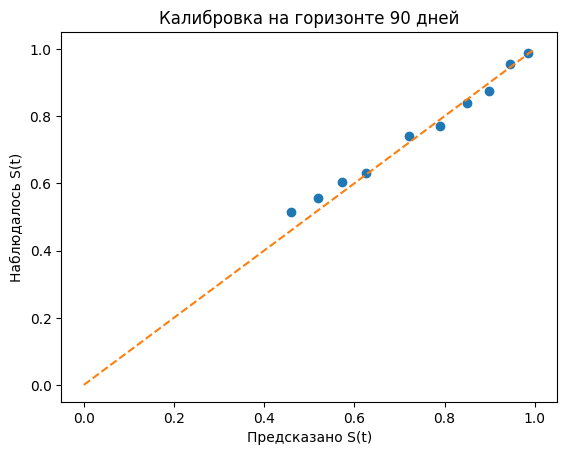

<Figure size 640x480 with 0 Axes>

<lifelines.KaplanMeierFitter:"Квантиль 1", fitted with 1870 total observations, 1807 right-censored observations>

<Axes: xlabel='timeline'>

<lifelines.KaplanMeierFitter:"Квантиль 2", fitted with 1870 total observations, 1618 right-censored observations>

<Axes: xlabel='timeline'>

...

<lifelines.KaplanMeierFitter:"Квантиль 4", fitted with 1870 total observations, 1224 right-censored observations>

<Axes: xlabel='timeline'>

Text(0.5, 1.0, 'KM‑кривые в группах риска')

Text(0.5, 0, 'Дни')

Text(0, 0.5, 'S(t)')

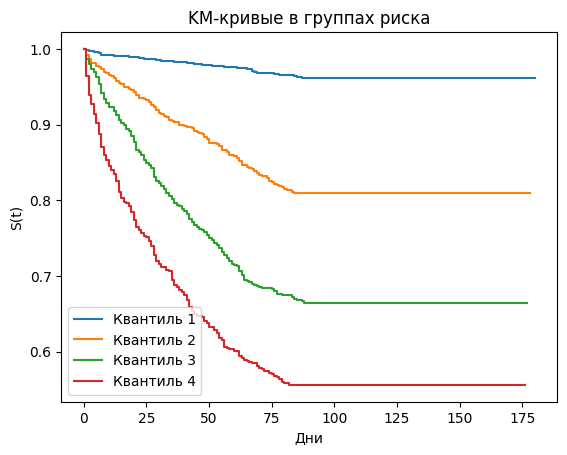

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'C-index (val)')

Text(0.5, 1.0, 'Динамика C-index')

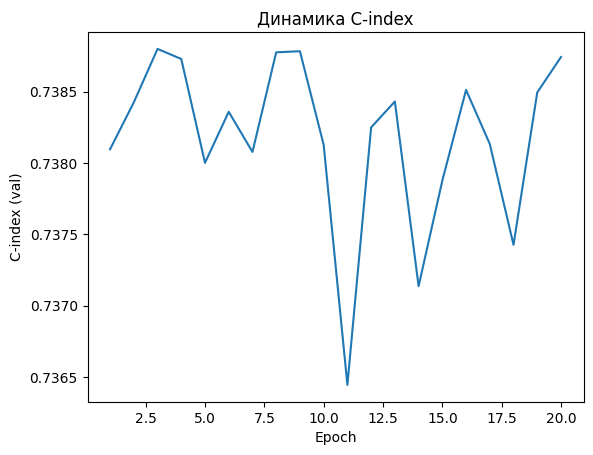

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from sksurv.metrics import (
    cumulative_dynamic_auc,
    brier_score,
    integrated_brier_score,
)
from sksurv.util import Surv

def baseline_survival(durations, events, risks):
    order = np.argsort(durations)
    uniq_t = np.unique(durations[order])
    # Бреслоу
    cum_hazard = []
    at_risk = np.exp(risks[order])[::-1].cumsum()[::-1]
    idx = 0
    cum = 0.0
    for t in uniq_t:
        mask = durations == t
        d_i = events[mask].sum()
        r_i = at_risk[idx]
        cum += d_i / r_i
        cum_hazard.append((t, cum))
        idx += mask.sum()
    cum_hazard = np.array(cum_hazard)
    s0 = np.exp(-cum_hazard[:, 1])
    return cum_hazard[:, 0], s0

t0, s0 = baseline_survival(
    y_train["duration"].values,
    y_train["event"].values,
    model.predict(X_train.values).ravel()
)

t_horiz = 90
s0_t = np.interp(t_horiz, t0, s0)


risk_test = model.predict(X_test.values).ravel()
s_hat = s0_t ** np.exp(risk_test)

quantiles = pd.qcut(s_hat, q=10, labels=False, duplicates='drop')
df_cal = pd.DataFrame({
    "bin": quantiles,
    "surv_pred": s_hat,
    "duration": y_test["duration"],
    "event": y_test["event"]
})

obs = []; exp = []
kmf = KaplanMeierFitter()
for b in sorted(df_cal.bin.unique()):
    sub = df_cal[df_cal.bin==b]
    kmf.fit(sub["duration"], sub["event"])
    obs.append(kmf.predict(t_horiz))
    exp.append(sub["surv_pred"].mean())

plt.plot(exp, obs, "o")
plt.plot([0,1], [0,1], "--")
plt.xlabel("Предсказано S(t)"); plt.ylabel("Наблюдалось S(t)")
plt.title(f"Калибровка на горизонте {t_horiz} дней")
plt.show()

n_groups = 4 
groups = pd.qcut(risk_test, q=n_groups, labels=False)
kmf = KaplanMeierFitter()
plt.figure()

for g in range(n_groups):
    mask = groups == g
    kmf.fit(durations=y_test["duration"][mask],
            event_observed=y_test["event"][mask],
            label=f"Квантиль {g+1}")
    kmf.plot_survival_function(ci_show=False)

plt.title("KM‑кривые в группах риска")
plt.xlabel("Дни"); plt.ylabel("S(t)")
plt.legend()
plt.show()

class ConcordanceCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val):
        self.X_val = X_val
        self.y_val = y_val
        self.history = []

    def on_epoch_end(self, epoch, logs=None):
        risk = self.model.predict(self.X_val, verbose=0).ravel()
        c_ind = concordance_index(self.y_val[:, 0], -risk, self.y_val[:, 1])
        self.history.append(c_ind)


try:
    from keras.saving import register_keras_serializable
except Exception:
    from tf.keras.utils import register_keras_serializable

@register_keras_serializable(package="survival")
def cox_ph_loss(y_true, y_pred):
    import tensorflow as tf
    events = tf.cast(y_true[:, 1], dtype=tf.float32)
    risk = tf.squeeze(y_pred, axis=-1)

    order = tf.argsort(y_true[:, 0], direction='DESCENDING')
    risk_ordered = tf.gather(risk, order)
    events_ordered = tf.gather(events, order)

    hazard_ratio = tf.exp(risk_ordered)
    log_cumsum = tf.math.log(tf.math.cumsum(hazard_ratio))
    diff = risk_ordered - log_cumsum
    loss = -tf.reduce_mean(diff * events_ordered)
    return loss
m2 = tf.keras.models.clone_model(model)
m2.build((None, X_train.shape[1]))
m2.set_weights(model.get_weights())
m2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss=cox_ph_loss)

cb = ConcordanceCallback(X_test.values, y_test[['duration','event']].values)
m2.fit(X_train.values, y_train[['duration','event']].values,
       epochs=20, batch_size=32, verbose=0, callbacks=[cb])

plt.plot(range(1, len(cb.history)+1), cb.history)
plt.xlabel('Epoch'); plt.ylabel('C-index (val)'); plt.title('Динамика C-index')
plt.show()

351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 530us/step


<Figure size 600x400 with 0 Axes>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


Text(0.5, 0, 'Время (duration)')

Text(0, 0.5, 'Вероятность выжить')

Text(0.5, 1.0, 'Прогнозные кривые выживаемости для выбранных объектов')

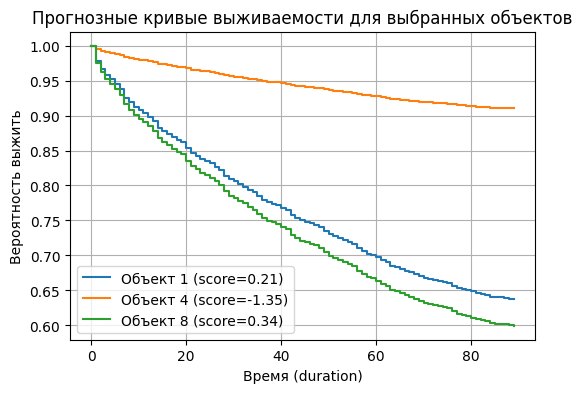

In [13]:
import matplotlib.pyplot as plt

durations_train = y_train['duration'].values
events_train = y_train['event'].values
pred_train = model.predict(X_train.values).flatten()

order = np.argsort(durations_train)
durations_train = durations_train[order]
events_train = events_train[order]
pred_train = pred_train[order]
exp_pred_train = np.exp(pred_train)

baseline_times = []
baseline_survival = []
cum_hazard = 0.0

unique_event_times = np.unique(durations_train[events_train == 1])
for t in unique_event_times:
    n_events = np.sum((durations_train == t) & (events_train == 1))
    risk_sum = np.sum(exp_pred_train[durations_train >= t])
    hazard_t = n_events / risk_sum
    cum_hazard += hazard_t
    baseline_times.append(t)
    baseline_survival.append(np.exp(-cum_hazard))

sample_indices = [1, 4, 8] 
plt.figure(figsize=(6,4))
for idx in sample_indices:
    score_i = model.predict(X_test.iloc[[idx]].values).flatten()[0]
    hr_i = np.exp(score_i)  
    surv_i = np.array(baseline_survival) ** hr_i
    plt.step(baseline_times, surv_i, where='post', label=f"Объект {idx} (score={score_i:.2f})")

plt.xlabel("Время (duration)")
plt.ylabel("Вероятность выжить")
plt.title("Прогнозные кривые выживаемости для выбранных объектов")
plt.legend()
plt.grid(True)
plt.show()

351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 469us/step


<Figure size 1000x600 with 0 Axes>

<lifelines.KaplanMeierFitter:"Low Risk", fitted with 5609 total observations, 5193 right-censored observations>

<lifelines.KaplanMeierFitter:"High Risk", fitted with 5610 total observations, 3875 right-censored observations>

<Axes: xlabel='timeline'>

<Axes: xlabel='timeline'>

Text(0.5, 1.0, 'Kaplan–Meier: группы риска')

Text(0.5, 0, 'Время')

Text(0, 0.5, 'Выживаемость')

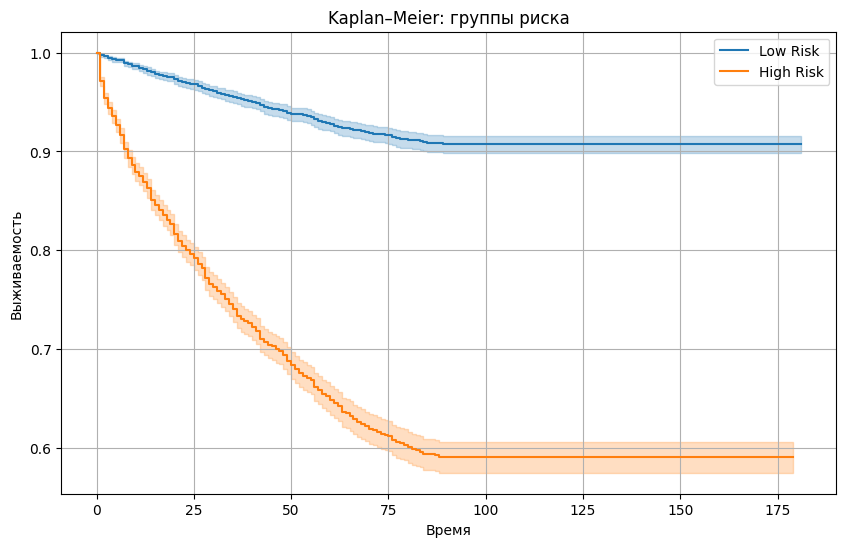

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

log_risk = model.predict(X_train).squeeze()

median_risk = np.median(log_risk)
low_risk_mask = log_risk < median_risk
high_risk_mask = log_risk >= median_risk

durations = y_train['duration'].values
events = y_train['event'].values

kmf_low = KaplanMeierFitter()
kmf_high = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

kmf_low.fit(durations[low_risk_mask], events[low_risk_mask], label='Low Risk')
kmf_high.fit(durations[high_risk_mask], events[high_risk_mask], label='High Risk')

kmf_low.plot(ci_show=True)
kmf_high.plot(ci_show=True)

plt.title("Kaplan–Meier: группы риска")
plt.xlabel("Время")
plt.ylabel("Выживаемость")
plt.legend()
plt.grid(True)
plt.show()


<Figure size 1200x1000 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Корреляционная матрица признаков')

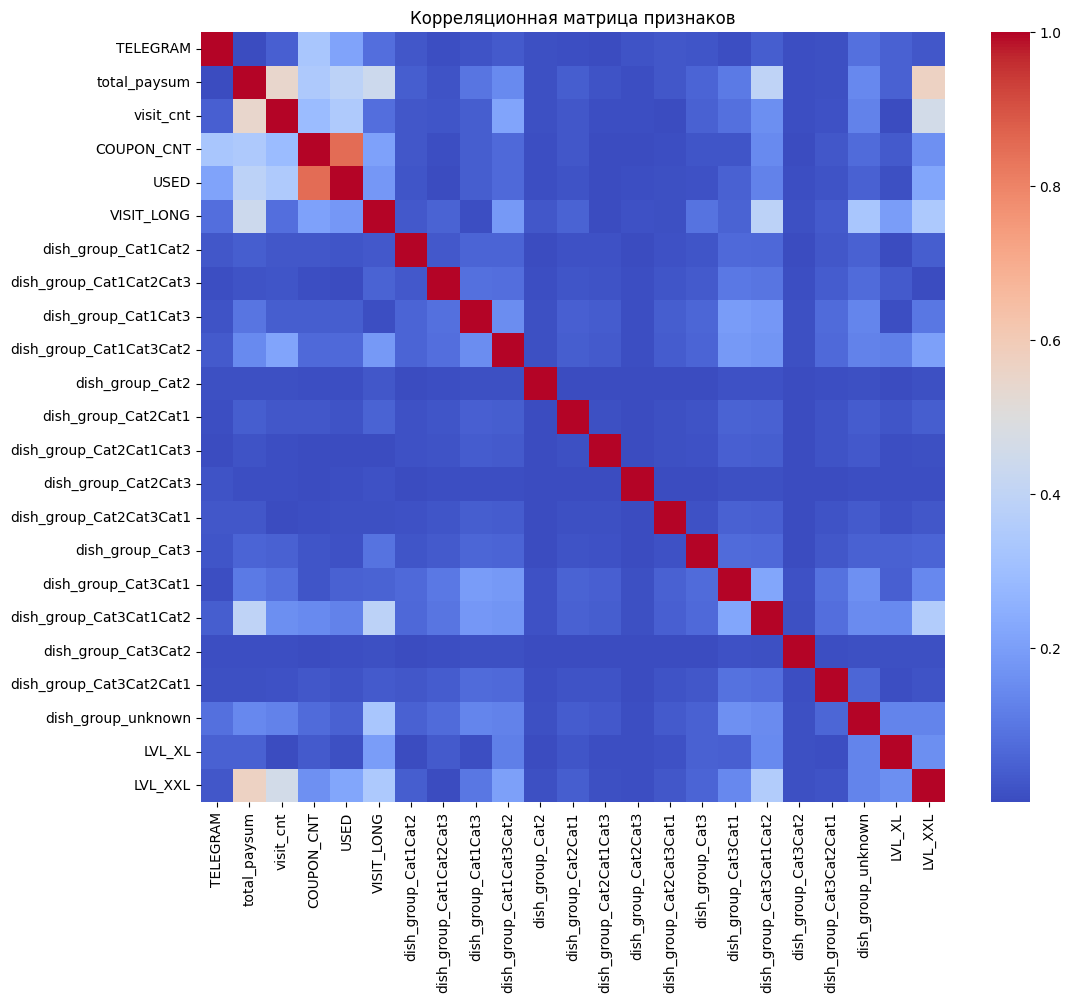

Признаки с высокой корреляцией (> 0.9):
[]
                    feature       VIF
0                     const  8.891021
4                COUPON_CNT  4.071075
5                      USED  3.896154
18  dish_group_Cat3Cat1Cat2  2.751423
2              total_paysum  2.226852
10  dish_group_Cat1Cat3Cat2  2.179837
17      dish_group_Cat3Cat1  2.122297
9       dish_group_Cat1Cat3  1.918656
23                  LVL_XXL  1.892338
6                VISIT_LONG  1.802373
3                 visit_cnt  1.751005
21       dish_group_unknown  1.645424
8   dish_group_Cat1Cat2Cat3  1.357620
20  dish_group_Cat3Cat2Cat1  1.249637
22                   LVL_XL  1.196077
1                  TELEGRAM  1.190692
16          dish_group_Cat3  1.147906
7       dish_group_Cat1Cat2  1.147248
12      dish_group_Cat2Cat1  1.079683
15  dish_group_Cat2Cat3Cat1  1.073552
13  dish_group_Cat2Cat1Cat3  1.065527
11          dish_group_Cat2  1.005274
19      dish_group_Cat3Cat2  1.004638
14      dish_group_Cat2Cat3  1.002918


In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = X_train.corr().abs()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Корреляционная матрица признаков")
plt.show()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = [column for column in upper.columns if any(upper[column] > 0.9)]

print("Признаки с высокой корреляцией (> 0.9):")
print(high_corr_pairs)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd

X_with_const = add_constant(X_train)
vif_data = pd.DataFrame()
vif_data["feature"] = X_with_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i) for i in range(X_with_const.shape[1])]

print(vif_data.sort_values(by="VIF", ascending=False))


